In [1]:
#importe das bibliotecas utilizadas

import cv2
import numpy as np
import matplotlib.pyplot as plt
import time


In [2]:
#Processamento de imagem usando open-cv (PRINCIPAL)
#Bruno Vanjura Vieira

def pegar_informacoes(caminho):
    # 1. Abrir o vÃ­deo
    video = cv2.VideoCapture(caminho)

    # InformaÃ§Ãµes do vÃ­deo
    fps = video.get(cv2.CAP_PROP_FPS)
    total_frames = video.get(cv2.CAP_PROP_FRAME_COUNT)

    duracao = total_frames / fps

    largura = int(video.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(video.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
    pixels_por_frame = largura * altura
    total_pixels_video = pixels_por_frame * total_frames

    print("FPS:", fps)
    print("Duraação:", duracao, "segundos")

    print(f"Resolução: {largura}x{altura}")
    print(f"Pixels por quadro: {pixels_por_frame}")
    print(f"Total de quadros: {total_frames}")
    print(f"Total de pixels no v­ídeo: {total_pixels_video}")

    video.release()

#Função para obter matriz M:

def obter_matriz_M(caminho_video, largura=160, altura=120):

    # Abrir o vÃ­deo
    video = cv2.VideoCapture(caminho_video)

    if not video.isOpened():
        raise Exception("NÃ£o foi possÃ­vel abrir o vÃ­deo!")

    # Extrair os quadros
    frames = []

    while True:
        ret, frame = video.read()

        if not ret:
            break

        # Converter para escala de cinza
        gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

        # Redimensionar os quadros
        gray = cv2.resize(gray, (largura, altura))

        frames.append(gray)

    video.release()

    # Verificar se foram extraÃ­dos quadros
    if len(frames) == 0:
        raise Exception("Nenhum quadro foi extraÃ­do!")

    # Vetorizar cada quadro
    vetores = [frame.flatten() for frame in frames]

    # Construir a matriz M
    M = np.column_stack(vetores).astype(float)

    return M

M = obter_matriz_M("data/caio_lutando.mp4") # obtendo M






In [3]:
#Funções de decomposição SVD

'''Decomposicao SVD'''
'''Parte 2: Joao Pedro Gomes Araujo Munhoz Ribeiro'''


EPS = np.finfo(float).eps


# Definicao da matriz devidamente formatada: M = A A^T
def Matriz(A):
    return A @ A.T


# Decompoe as matrizes Q e R
def Matrizes_Q_R(M):
    Q, R = np.linalg.qr(M)
    return Q, R


# Calculo dos valores singulares 
def Singulares_QR(B, tol=1e-15, max_iter=5000):
    W = np.array(B, dtype=float)

    for k in range(max_iter):
        Qk, Rk = Matrizes_Q_R(W)
        W = Rk @ Qk
      
        off = np.linalg.norm(W - np.diag(np.diag(W)))
        if off <= tol * np.linalg.norm(W):
            break

    lam = np.diag(W).real
    lam = np.maximum(lam, 0.0)         
    autoval = np.sqrt(lam)
    return np.sort(autoval)[::-1]


#Calculo dos Autovetores da direita
def Autovetores_Direita(A, autv, tol=1e-15, iter=100):
    A = np.array(A, dtype=float)
    n = A.shape[0]
    I = np.eye(n)
    normaA = np.linalg.norm(A)
    rng = np.random.default_rng(0)
    autovetores = []

    for k in range(n):
        lam = autv[k] ** 2                      
        mu = lam + 10 * EPS * normaA             
        B = A - mu * I

        qold = rng.random(n) - 0.5
        qold /= np.linalg.norm(qold)

        norm = 1
        cont = 0
        while norm > tol and cont < iter:
            try:
                qnew = np.linalg.solve(B, qold)
            except np.linalg.LinAlgError:
                mu += 10 * EPS * normaA
                B = A - mu * I
                continue

            for _ in range(2):
                for q in autovetores:
                    qnew = qnew - np.dot(q, qnew) * q

            qnew = qnew / np.linalg.norm(qnew)
            norm = 1 - np.abs(np.vdot(qold, qnew))
            qold = qnew
            cont += 1

        autovetores.append(qold)                 

    return np.array(autovetores)                

#Calculo dos autovetores da esquerda
def Autovetores_esquerda(A, autovec, autoval):
    n = len(autoval)
    v = []
    sig = np.zeros(n)
    for i in range(n):
        w = A.T @ autovec[i]
        sig[i] = np.linalg.norm(w)              
        v.append(w / sig[i] if sig[i] > 0 else w)
    v = np.array(v)

    
    for i in range(n):
        for _ in range(2):
            for j in range(i):
                v[i] = v[i] - np.dot(v[j], v[i]) * v[j]
        nv = np.linalg.norm(v[i])
        if nv > 0:
            v[i] = v[i] / nv
    return v, sig

#Definicao das matrizes
def Matrizes(A, AutovecL, AutovecR, Autoval):
    n = A.shape[0]
    S = np.eye(n)
    for j in range(n):
        S[j][j] = Autoval[j]

    U = np.array(AutovecL).T      
    Vt = np.array(AutovecR)        
    return U, S, Vt

#Funcao final
def DecompsicaoSVD(A):
    A = np.array(A, dtype=float)
    inicio = time.perf_counter()
    M = Matriz(A)
    ValoresSingulares = Singulares_QR(M)
    U_vec = Autovetores_Direita(M, ValoresSingulares)          
    V_vec, sig = Autovetores_esquerda(A, U_vec, ValoresSingulares)  
    U, S, Vt = Matrizes(A, U_vec, V_vec, sig)
    fim = time.perf_counter()
    return U, S, Vt, fim - inicio

In [4]:
# Decomposicao SVD pelo metodo de Jacobi

# Calcula os coeficientes da rotacao que zera a entrada A[p, q].
def matriz_rotacao_jacobi(A, p, q):
    phi = (A[q, q] - A[p, p]) / (2.0 * A[p, q])
    if phi == 0:
        t = 1.0
    else:
        t = 1.0 / (phi + np.copysign(1.0, phi) * np.sqrt(phi**2 + 1.0))
    c = 1.0 / np.sqrt(1.0 + t**2)
    s = t * c
    return c, s


# Encontra o maior elemento fora da diagonal para verificar a convergencia.
def find_position(A):
    if A.shape[0] < 2:
        return 0, 0, 0.0
    fora_diagonal = np.triu(np.abs(A), k=1)
    p, q = np.unravel_index(np.argmax(fora_diagonal), fora_diagonal.shape)
    return p, q, fora_diagonal[p, q]


# Diagonaliza a matriz simetrica A e acumula seus autovetores nas colunas de V.
def solve_jacobi(A, tol=1e-12, max_sweeps=100):
    A = np.asarray(A, dtype=float)
    if A.ndim != 2 or A.shape[0] != A.shape[1] or A.shape[0] == 0:
        raise ValueError("A deve ser uma matriz quadrada nao vazia.")

    A = 0.5 * (A + A.T)  # Remove pequenas assimetrias de arredondamento.
    n = A.shape[0]
    V = np.eye(n)
    tol_absoluta = tol * max(1.0, np.linalg.norm(A, ord="fro"))

    for iteracao in range(max_sweeps):
        # Cada par (p, q) define uma rotacao de Jacobi em um plano.
        for p in range(n - 1):
            for q in range(p + 1, n):
                apq = A[p, q]
                if abs(apq) <= tol_absoluta:
                    continue

                c, s = matriz_rotacao_jacobi(A, p, q)
                app, aqq = A[p, p], A[q, q]
                A[p, p] = app - (s / c) * apq
                A[q, q] = aqq + (s / c) * apq
                A[p, q] = A[q, p] = 0.0

                # Atualiza as linhas e colunas afetadas pela rotacao.
                for k in range(n):
                    if k != p and k != q:
                        akp, akq = A[k, p], A[k, q]
                        A[k, p] = A[p, k] = c * akp - s * akq
                        A[k, q] = A[q, k] = s * akp + c * akq

                # Aplica a rotacao aos autovetores acumulados.
                v_p, v_q = V[:, p].copy(), V[:, q].copy()
                V[:, p] = c * v_p - s * v_q
                V[:, q] = s * v_p + c * v_q

        _, _, maior_fora_diagonal = find_position(A)
        if maior_fora_diagonal <= tol_absoluta:
            break
    else:
        raise RuntimeError(
            f"Jacobi nao convergiu em {max_sweeps} varreduras; "
            f"maior elemento fora da diagonal = {maior_fora_diagonal:.3e}."
        )

    return np.diag(A).copy(), V


def DecomposicaoSVD_Jacobi(M, tol=1e-12, max_sweeps=100):
    inicio = time.perf_counter()
    M = np.asarray(M, dtype=float)
    if M.ndim != 2 or M.shape[0] == 0 or M.shape[1] == 0:
        raise ValueError("M deve ser uma matriz nao vazia.")

    # Pela formulacao do projeto, A = M^T M e seus autovetores sao os v_i.
    A = M.T @ M
    autovalores, V = solve_jacobi(A, tol=tol, max_sweeps=max_sweeps)

    # Ordena lambda_i em ordem decrescente e reorganiza as colunas de V.
    ordem = np.argsort(autovalores)[::-1]
    autovalores = autovalores[ordem]
    V = V[:, ordem]

    # Descarta autovalores que sao apenas erro numerico.
    lambda_max = max(autovalores[0], 0.0)
    tol_lambda = np.finfo(float).eps * max(M.shape) * lambda_max
    posto = autovalores > tol_lambda
    lambda_i = autovalores[posto]
    V_r = V[:, posto]

    # sigma_i = sqrt(lambda_i) e u_i = M v_i / sigma_i.
    sigma_i = np.sqrt(np.maximum(lambda_i, 0.0))
    U_r = (M @ V_r) / sigma_i[np.newaxis, :]
    Sigma_r = np.diag(sigma_i)

    tempo = time.perf_counter() - inicio
    return U_r, Sigma_r, V_r, tempo


# Teste pequeno: verifica a reconstrucao M = U_r Sigma_r V_r^T.
M_teste = np.array([[1.0, 2.0, 3.0], [9.0, 0.0, 7.0], [2.0, 5.0, 0.0]])
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M_teste)
erro_reconstrucao = np.linalg.norm(M_teste - U_r @ Sigma_r @ V_r.T, ord="fro")
print("Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("Erro de reconstrucao:", erro_reconstrucao)
print("Tempo de execucao do metodo de Jacobi:", tempo_jacobi, "segundos")

Dimensoes de U_r, Sigma_r e V_r: (3, 3) (3, 3) (3, 3)
Erro de reconstrucao: 8.316947185256325e-15
Tempo de execucao do metodo de Jacobi: 0.023112218999813194 segundos


In [5]:
# Comparacao com o svd nativo utilizando uma matriz pequena para diminuir o custo computacional:
A = np.array([[1,2,3],[9,0,7],[2,5,0]]) 

u, s, v, t = DecompsicaoSVD(A)
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(A)

inip = time.perf_counter()
m, n, p = np.linalg.svd(A)
fimp = time.perf_counter()
tp = fimp - inip

erro_reconstrucao_QR = np.linalg.norm(A - u @ s @ v.T, ord="fro")
print("\nQR: Dimensoes de u, s e v:", u.shape, s.shape, v.shape)
print("\nErro de reconstrucao:", erro_reconstrucao_QR)
print("\nSolução QR:\nU =\n", u, "\nS =\n", s, "\nVt =\n", v)
print("\nTempo da solução QR:", t)


erro_reconstrucao_J = np.linalg.norm(A - U_r @ Sigma_r @ V_r.T, ord="fro")
print("\nJacobi: Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("\nErro de reconstrucao:", erro_reconstrucao_J)
print("\nSolução pelo método de Jacobi:\nu_J =\n", U_r, "\ns_J =\n", Sigma_r, "\nvt_J =\n", V_r)
print("\nTempo da solução pelo método de Jacobi:", tempo_jacobi)
print("\nSolucao do programa:\nU =\n", m, "\nS =\n", n, "\nVt =\n", p, "\nT = ", tp)

print("\nErro na aproximacao em relação à QR:\n")

eU = m - u
eS = np.dot(n, np.eye(A.shape[0])) - s
eV = v - p


print("\nErro de U:\n ", eU)
print("\nErro de S:\n ", eS)
print("\nErro de V:\n ", eV)

print("\nErro na aproximacao em relação à Jacobi:\n")

eU = m - U_r
eS = np.dot(n, np.eye(A.shape[0])) - Sigma_r
eV = V_r - p


print("\nErro de U:\n ", eU)
print("\nErro de S:\n ", eS)
print("\nErro de V:\n ", eV)




QR: Dimensoes de u, s e v: (3, 3) (3, 3) (3, 3)

Erro de reconstrucao: 2.1231928160616396

Solução QR:
U =
 [[-0.24217417  0.27582641  0.93019969]
 [-0.95354174 -0.24473231 -0.17568222]
 [-0.17919212  0.92952993 -0.32227984]] 
S =
 [[11.87441822  0.          0.        ]
 [ 0.          5.274628    0.        ]
 [ 0.          0.          2.04364658]] 
Vt =
 [[-0.77329549 -0.11624224 -0.62329914]
 [-0.01283588  0.98571927 -0.16790699]
 [-0.63391586  0.12184113  0.76374434]]

Tempo da solução QR: 0.02593531099955726

Jacobi: Dimensoes de U_r, Sigma_r e V_r: (3, 3) (3, 3) (3, 3)

Erro de reconstrucao: 8.316947185256325e-15

Solução pelo método de Jacobi:
u_J =
 [[ 0.24217417  0.27582641  0.93019969]
 [ 0.95354174 -0.24473231 -0.17568222]
 [ 0.17919212  0.92952993 -0.32227984]] 
s_J =
 [[11.87441822  0.          0.        ]
 [ 0.          5.274628    0.        ]
 [ 0.          0.          2.04364658]] 
vt_J =
 [[ 0.77329549 -0.01283588 -0.63391586]
 [ 0.11624224  0.98571927  0.12184113]
 [ 0

In [6]:
# Parte 3 APROXIMAÃ‡ÃƒO DE BAIXO POSTO 
def aproximacao_baixo_posto(U, S, Vt, k):
    # Calcula a aproximaÃ§Ã£o de posto no mÃ¡ximo k (Eq. 11):
    # Garante que os valores singulares estejam em um vetor 1D
    s = np.diag(S) if S.ndim == 2 else S
    r = len(s)

    if not (1 <= k <= r):
        raise ValueError(f"k deve estar entre 1 e {r}.")

    # MantÃ©m apenas os k maiores valores singulares e seus vetores correspondentes
    U_k = U[:, :k]
    Sigma_k = np.diag(s[:k])
    Vt_k = Vt[:k, :]

    L_k = U_k @ Sigma_k @ Vt_k
    return L_k


def avaliar_aproximacao(M, L_k, s=None, k=None):
    """
    Calcula o erro na norma de Frobenius ||M - L_k||_F (Eq. 12)
    e o erro relativo percentual.
    """
    erro_frob = np.linalg.norm(M - L_k, ord='fro')
    norma_M = np.linalg.norm(M, ord='fro')
    erro_relativo = erro_frob / norma_M

    resultado = {
        "erro_frobenius": erro_frob,
        "erro_relativo": erro_relativo,
    }

    # VerificaÃ§Ã£o teÃ³rica: ||M - L_k||_F = sqrt(sum_{i=k+1}^r sigma_i^2)
    if s is not None and k is not None:
        s_vec = np.diag(s) if s.ndim == 2 else s
        resultado["erro_teorico_sigmas"] = np.sqrt(np.sum(s_vec[k:] ** 2))

    return resultado

# 1. Obter a matriz M do vÃ­deo
largura, altura = 160, 120
M = obter_matriz_M("data/caio_lutando.mp4", largura=largura, altura=altura)

# 2. Calcular a SVD reduzida de M (M = U @ diag(s) @ Vt)
U, s, Vt = np.linalg.svd(M, full_matrices=False)
r = len(s)
print(f"DimensÃ£o de M: {M.shape} | Posto mÃ¡ximo r: {r}")

# 3. Testar diferentes valores de posto k <= r (arbitrários)
valores_k = [1, 2, 3, 4, 5, 10, 20, 100]
valores_k = [k for k in valores_k if k <= r]

aproximacoes = {}
for k in valores_k:
    L_k = aproximacao_baixo_posto(U, s, Vt, k)
    metricas = avaliar_aproximacao(M, L_k, s=s, k=k)
    aproximacoes[k] = L_k

    print(
        f"k = {k:2d} | "
        f"||M - L_k||_F = {metricas['erro_frobenius']:.4f} | "
        f"TeÃ³rico = {metricas['erro_teorico_sigmas']:.4f} | "
        f"Erro relativo = {metricas['erro_relativo']*100:.2f}%"
    )

DimensÃ£o de M: (19200, 286) | Posto mÃ¡ximo r: 286
k =  1 | ||M - L_k||_F = 39408.2242 | TeÃ³rico = 39408.2242 | Erro relativo = 14.12%
k =  2 | ||M - L_k||_F = 34116.2918 | TeÃ³rico = 34116.2918 | Erro relativo = 12.22%
k =  3 | ||M - L_k||_F = 29667.3261 | TeÃ³rico = 29667.3261 | Erro relativo = 10.63%
k =  4 | ||M - L_k||_F = 27629.4695 | TeÃ³rico = 27629.4695 | Erro relativo = 9.90%
k =  5 | ||M - L_k||_F = 26298.0019 | TeÃ³rico = 26298.0019 | Erro relativo = 9.42%
k = 10 | ||M - L_k||_F = 22448.2125 | TeÃ³rico = 22448.2125 | Erro relativo = 8.04%
k = 20 | ||M - L_k||_F = 18788.7216 | TeÃ³rico = 18788.7216 | Erro relativo = 6.73%
k = 100 | ||M - L_k||_F = 9917.9439 | TeÃ³rico = 9917.9439 | Erro relativo = 3.55%


[1, 2, 3, 4, 5, 10, 20, 100]


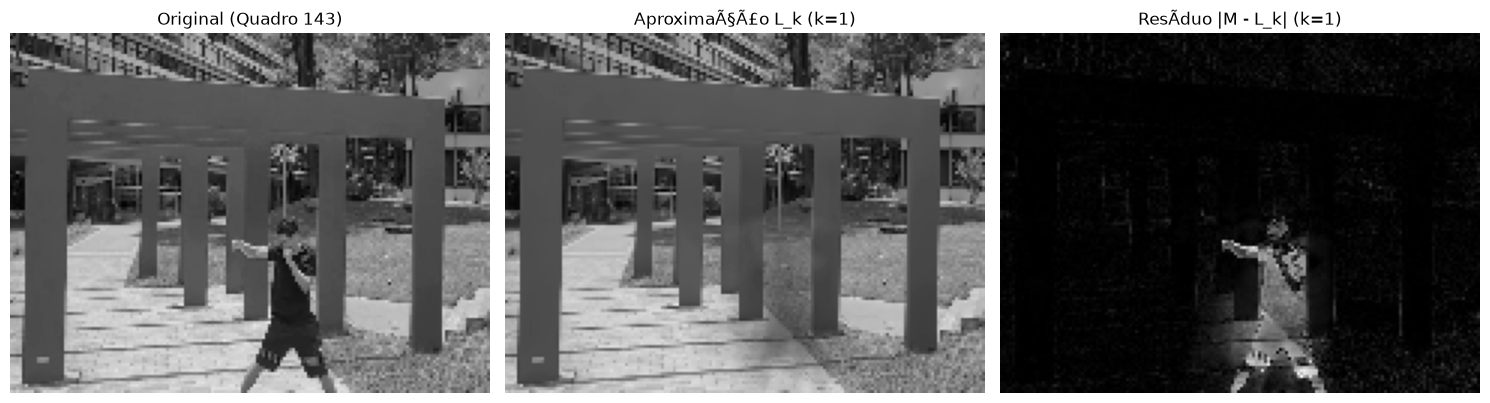

In [7]:
print(valores_k)

# VisualizaÃ§Ã£o dos quadros reconstruÃ­dos (Lk e do resÃ­duo (M - Lk))
idx_quadro = M.shape[1] // 2  # Quadro central do vÃ­deo (PRA TESTE)
k_escolhido = valores_k[0]    # Defina o k que deseja de 0 a 7 (1, 2, 3, 4, 5, 10, 20, 100)
L_k = aproximacoes[k_escolhido] # influencia no quÃ£o bom Ã© o recorte 

quadro_original = M[:, idx_quadro].reshape((altura, largura))
quadro_Lk = np.clip(L_k[:, idx_quadro].reshape((altura, largura)), 0, 255)
quadro_residuo = np.abs(M[:, idx_quadro] - L_k[:, idx_quadro]).reshape((altura, largura))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

axes[0].imshow(quadro_original, cmap='gray', vmin=0, vmax=255)
axes[0].set_title(f"Original (Quadro {idx_quadro})")
axes[0].axis('off')

axes[1].imshow(quadro_Lk, cmap='gray', vmin=0, vmax=255)
axes[1].set_title(f"AproximaÃ§Ã£o L_k (k={k_escolhido})")
axes[1].axis('off')

axes[2].imshow(quadro_residuo, cmap='gray')
axes[2].set_title(f"ResÃ­duo |M - L_k| (k={k_escolhido})")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [8]:
# Parte 4: Identificação de Movimento
# Caio Lucas Indalécio

def mat_res(M, L_k):
    R_k = M - L_k # Dada uma matriz e um L_k, calcula-se o resí­duo R_k (movimento)
    S_k = np.abs(R_k) # S_k é uma matriz cujos elementos são o módulo dos elementos de R_k
    return R_k, S_k

# Criando uma mascara binÃ¡ria
def mask(S_k):
    threshold = 50
    # Mask é uma matriz que transforma os valores acima de um limiar em 1 e abaixo ou igual em zero
    # Mask é, portanto, uma máscara binária.
    mask = (S_k > threshold).astype(np.uint8)
    return mask

# Nota-se que quanto maior o threshold

In [9]:
# Parte 5: Reconstrução do vídeo
# Luiz Gustavo Borges e Cunha - Rizzioli não fez nada

def recontruir_video(M, L_k, S_k, caminho_original, caminho_saida,
                     largura_matriz=160, altura_matriz=120):
    """Gera um vídeo lado a lado: original, fundo aproximado e movimento."""
    captura = cv2.VideoCapture(caminho_original)
    if not captura.isOpened():
        raise ValueError("Não foi possível abrir o vídeo original.")

    largura = int(captura.get(cv2.CAP_PROP_FRAME_WIDTH))
    altura = int(captura.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = captura.get(cv2.CAP_PROP_FPS)

    if L_k.shape != M.shape or S_k.shape != M.shape:
        captura.release()
        raise ValueError("M, L_k e S_k devem ter as mesmas dimensões.")

    codec = cv2.VideoWriter_fourcc(*"mp4v")
    video = cv2.VideoWriter(caminho_saida, codec, fps, (3 * largura, altura))
    if not video.isOpened():
        captura.release()
        raise ValueError("Não foi possível criar o vídeo de saída.")

    try:
        for i in range(M.shape[1]):
            ret, original = captura.read()
            if not ret:
                raise ValueError("O vídeo original tem menos quadros que M.")

            fundo = L_k[:, i].reshape((altura_matriz, largura_matriz))
            fundo = np.clip(fundo, 0, 255).astype(np.uint8)
            fundo = cv2.resize(fundo, (largura, altura))
            fundo = cv2.cvtColor(fundo, cv2.COLOR_GRAY2BGR)

            movimento = S_k[:, i].reshape((altura_matriz, largura_matriz))
            mascara = mask(movimento) * 255
            mascara = cv2.resize(
                mascara, (largura, altura), interpolation=cv2.INTER_NEAREST
            )
            regioes_movimento = cv2.bitwise_and(
                original, original, mask=mascara
            )

            # Cada quadro de saída reúne os três painéis na ordem do projeto.
            video.write(np.hstack((original, fundo, regioes_movimento)))
    finally:
        captura.release()
        video.release()

    print(f"Vídeo comparativo salvo em: {caminho_saida}")

# Calcula o resíduo e as regiões de movimento para o posto escolhido.
R_k, S_k = mat_res(M, L_k)
'''recontruir_video(
    M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.avi",
    largura_matriz=largura, altura_matriz=altura
)'''



'recontruir_video(\n    M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.avi",\n    largura_matriz=largura, altura_matriz=altura\n)'

In [10]:
#Código principal:

#Tratamento do vídeo, tranformando-o em matriz
pegar_informacoes("data/caio_lutando.mp4") #Começando extraindo informações do vídeo original
M = obter_matriz_M("data/caio_lutando.mp4") #Usando a função criada para obter a matriz M

#Cálculo da SVD
U_r, Sigma_r, V_r, tempo_jacobi = DecomposicaoSVD_Jacobi(M)
erro_reconstrucao = np.linalg.norm(M - U_r @ Sigma_r @ V_r.T, ord="fro")
print("\nJacobi: Dimensoes de U_r, Sigma_r e V_r:", U_r.shape, Sigma_r.shape, V_r.shape)
print("Erro de reconstrucao:", erro_reconstrucao)
print("Tempo de execucao do metodo de Jacobi:", tempo_jacobi, "segundos\n")
'''u_qr, s_qr, v_qr, t_qr = DecompsicaoSVD(M)
erro_reconstrucao_qr = np.linalg.norm(M - u_qr @ s_qr @ v_qr.T, ord="fro")
print("\nJacobi: Dimensoes de U_QR, Sigma_QR e V_QR:", u_qr.shape, s_qr.shape, v_qr.shape)
print("Erro de reconstrucao:", erro_reconstrucao_qr)
print("Tempo de execucao do metodo de Jacobi:", t_qr, "segundos\n")'''
u, s, v = np.linalg.svd(M) #rotina pronta de SVD

#Aproximação de baixo posto
L_k = aproximacao_baixo_posto(u, s, v, 1)

#Identificação do movimento
R_k, S_k = mat_res(M, L_k)

#Recontrução do vídeo
recontruir_video(M, L_k, S_k, "data/caio_lutando.mp4", "data/video_reconstruido.mp4",largura_matriz=largura, altura_matriz=altura)




FPS: 30.0
Duraação: 9.533333333333333 segundos
Resolução: 1920x1080
Pixels por quadro: 2073600
Total de quadros: 286
Total de pixels no v­ídeo: 593049600

Jacobi: Dimensoes de U_r, Sigma_r e V_r: (19200, 286) (286, 286) (286, 286)
Erro de reconstrucao: 9.639357465865356e-09
Tempo de execucao do metodo de Jacobi: 40.01158237300115 segundos

Vídeo comparativo salvo em: data/video_reconstruido.mp4
